In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')

from matplotlib import pyplot as plt
import polars as pl
import numpy as np

# Loading data

In [2]:
data = pl.read_csv('../data/random5.csv').with_columns(
    pl.col("time").str.json_decode(dtype=pl.List(pl.Float64)),
    pl.col("flux").str.json_decode(dtype=pl.List(pl.Float64)),
)
print(data.height)
display(data.head(5))

def get_lc(row_idx=0):
    row = data.slice(row_idx, 1)
    time = row['time'][0].to_numpy()
    flux = row['flux'][0].to_numpy()
    return row['path'][0], time, flux
    
%timeit -r100 -n100 get_lc(10)

40


path,label,time,flux
str,str,list[f64],list[f64]
"""/STER/mamsie/tess/TIC/tglc_scr…","""APERIODIC""","[2010.283668, 2010.304502, … 2034.763084]","[0.999594, 1.001175, … 0.999424]"
"""/STER/mamsie/tess/TIC/tglc_scr…","""APERIODIC""","[1711.388222, 1711.409055, … 1737.325414]","[0.999952, 0.99906, … 0.99857]"
"""/STER/mamsie/tess/TIC/tglc_scr…","""APERIODIC""","[2010.283668, 2010.304502, … 2034.804751]","[0.99963, 0.999506, … 0.999463]"
"""/STER/mamsie/tess/TIC/tglc_scr…","""APERIODIC""","[1683.367406, 1683.388239, … 1710.179597]","[1.000021, 0.999826, … 0.999793]"
"""/STER/mamsie/tess/TIC/tglc_scr…","""APERIODIC""","[2419.999024, 2420.005968, … 2446.575108]","[1.000359, 1.000199, … 0.999855]"


5.83 μs ± 1.24 μs per loop (mean ± std. dev. of 100 runs, 100 loops each)


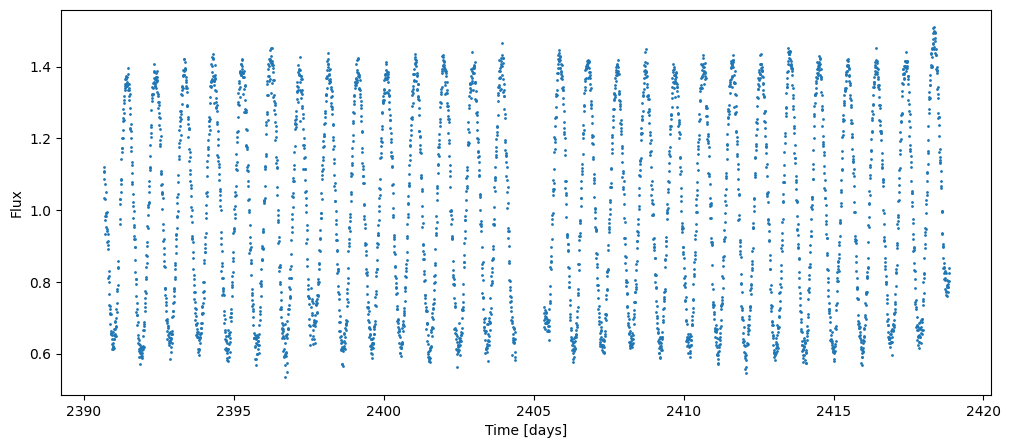

In [3]:
oid, time, flux = get_lc(8)

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(time, flux, s=1)
ax.set_xlabel('Time [days]')
ax.set_ylabel('Flux');

# Time domain features

In [4]:
from time_domain_features import flux_statistics, max_slope

display(flux_statistics(flux))
display(max_slope(time, flux))

{'flux_std': 0.27949697801821377,
 'flux_skewness': 0.06301685871284048,
 'flux_kurtosis': -1.463523634214852,
 'flux_iqr': 0.5494450330734253,
 'flux_amplitude': 0.3928571492433548,
 'flux_mad': 0.2740292549133301,
 'flux_largest_departure': 0.5293999877073138,
 'flux_percent_difference': 0.7958909643564024,
 'flux_ratio_mid20': 0.30958492686122774,
 'flux_ratio_mid45': 0.5200472633397483,
 'flux_ratio_mid50': 0.6992936670895002,
 'flux_ratio_mid65': 0.8444949982736056,
 'flux_ratio_mid80': 0.9393986094095716}

{'max_slope': 22.313517207787896}

In [5]:
times, fluxes = [], []
for k in range(data.height):
    oid, time_, flux_ = get_lc(k)
    times.append(time_)
    fluxes.append(flux_)    
    
%timeit -r10 -n10 [flux_statistics(flux) for flux in fluxes]
%timeit -r10 -n10 [max_slope(time, flux) for time, flux in zip(times, fluxes)]

14.2 ms ± 1.38 ms per loop (mean ± std. dev. of 10 runs, 10 loops each)
491 μs ± 45.7 μs per loop (mean ± std. dev. of 10 runs, 10 loops each)


# Periodogram

{'ls_fundamental_log_10_frequency': 0.016996021116837488,
 'ls_fundamental_log_10_fap': -307.6526555685888}

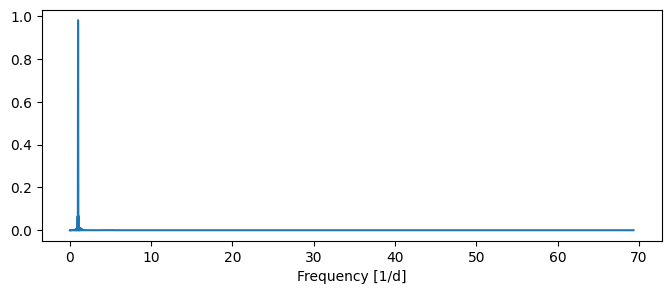

In [6]:
from frequency_domain_features import lombscargle_periodogram, frequency_grid, periodogram_features

dts = np.mean(time[1:] - time[:-1])
T = time[-1] - time[0]
0.5/dts, 1/T
fmin, fmax, fres = 1/T, 0.5/dts, 0.1/T

freqs = frequency_grid(fmin, fmax, fres)
ampls = lombscargle_periodogram(time, flux, fmin, fmax, fres)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(freqs, ampls)
ax.set_xlabel('Frequency [1/d]')

pg = periodogram_features(time, flux, peaks_to_finetune=10)
pg

In [7]:
%timeit -r3 -n3 [periodogram_features(time, flux, peaks_to_finetune=10) for time, flux in zip(times, fluxes)]

296 ms ± 13.3 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)


{'fourier_amplitude_1': 0.3918953971260283,
 'fourier_amplitude_2': 0.011171123570162221,
 'fourier_amplitude_3': 0.002278673868610437,
 'fourier_amplitude_4': 0.0015468811529614694,
 'fourier_relative_phase_2': -0.9246225690712677,
 'fourier_relative_phase_3': 1.3158682432086364,
 'fourier_relative_phase_4': -2.926576295628939,
 'fourier_r2_fit': np.float64(0.9842060612570233)}

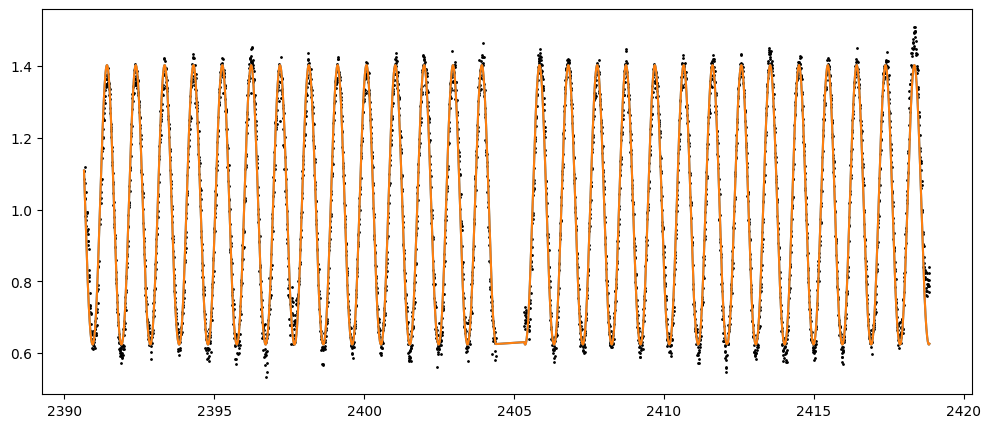

In [8]:
from frequency_domain_features import fourier_series_design_matrix, fit_fourier_series, fourier_series_features

n_components = 4
best_freq = 10 ** pg['ls_fundamental_log_10_frequency']
X = fourier_series_design_matrix(time, best_freq, n_components)
theta, amplitudes, phases, _ = fit_fourier_series(time, flux, best_freq, n_components)
model_flux = theta[0] + np.sum(np.stack([a*np.cos(2*np.pi*time*(k+1)*best_freq - p) for k, (a, p) in enumerate(zip(amplitudes, phases))]), axis=0)

plt.figure(figsize=(12, 5))
plt.scatter(time, flux, s=1, c='k')
plt.plot(time, np.dot(X, theta))
plt.plot(time, model_flux)
fourier_series_features(time, flux, best_freq, n_components)

In [9]:
%timeit -r3 -n3 [fourier_series_features(time, flux, best_freq, n_components) for time, flux in zip(times, fluxes)]

14 ms ± 194 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)


In [10]:
from feature_extractor import extract_features

%timeit -r3 -n3 [extract_features(time, flux) for time, flux in zip(times, fluxes)]


350 ms ± 13.7 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)
